In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, GridSearchCV
from xgboost import XGBRegressor

## In this project, I will analyze a Kaggle dataset of used cars. 

In [3]:
data_original = pd.read_csv('vehicles.csv')

data = data_original.copy()

### Data inspection and cleaning

In [4]:
data.head(20)

,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,size,type,paint_color,image_url,description,county,state,lat,long,posting_date
0,7222695916,https://prescott.craigslist.org/cto/d/prescott...,prescott,https://prescott.craigslist.org,6000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,az,NaN,NaN,NaN
1,7218891961,https://fayar.craigslist.org/ctd/d/bentonville...,fayetteville,https://fayar.craigslist.org,11900,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ar,NaN,NaN,NaN
2,7221797935,https://keys.craigslist.org/cto/d/summerland-k...,florida keys,https://keys.craigslist.org,21000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,fl,NaN,NaN,NaN
3,7222270760,https://worcester.craigslist.org/cto/d/west-br...,worcester / central MA,https://worcester.craigslist.org,1500,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ma,NaN,NaN,NaN
4,7210384030,https://greensboro.craigslist.org/cto/d/trinit...,greensboro,https://greensboro.craigslist.org,4900,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,nc,NaN,NaN,NaN
5,7222379453,https://hudsonvalley.craigslist.org/cto/d/west...,hudson valley,https://hudsonvalley.craigslist.org,1600,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ny,NaN,NaN,NaN
6,7221952215,https://hudsonvalley.craigslist.org/cto/d/west...,hudson valley,https://hudsonvalley.craigslist.org,1000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ny,NaN,NaN,NaN
7,7220195662,https://hudsonvalley.craigslist.org/cto/d/poug...,hudson valley,https://hudsonvalley.craigslist.org,15995,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ny,NaN,NaN,NaN
8,7209064557,https://medford.craigslist.org/cto/d/grants-pa...,medford-ashland,https://medford.craigslist.org,5000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,or,NaN,NaN,NaN
9,7219485069,https://erie.craigslist.org/cto/d/erie-2012-su...,erie,https://erie.craigslist.org,3000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,pa,NaN,NaN,NaN


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 26 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   url           426880 non-null  str    
 2   region        426880 non-null  str    
 3   region_url    426880 non-null  str    
 4   price         426880 non-null  int64  
 5   year          425675 non-null  float64
 6   manufacturer  409234 non-null  str    
 7   model         421603 non-null  str    
 8   condition     252776 non-null  str    
 9   cylinders     249202 non-null  str    
 10  fuel          423867 non-null  str    
 11  odometer      422480 non-null  float64
 12  title_status  418638 non-null  str    
 13  transmission  424324 non-null  str    
 14  VIN           265838 non-null  str    
 15  drive         296313 non-null  str    
 16  size          120519 non-null  str    
 17  type          334022 non-null  str    
 18  paint_color   2

In [6]:
data = data.drop_duplicates()

In [7]:
missing_values = data.isnull().sum()

missing_values_pct = (missing_values / len(data)) * 100

missing_values_pct.sort_values(ascending=False)

county          100.000000
size             71.767476
cylinders        41.622470
condition        40.785232
VIN              37.725356
drive            30.586347
paint_color      30.501078
type             21.752717
manufacturer      4.133714
title_status      1.930753
lat               1.534155
long              1.534155
model             1.236179
odometer          1.030735
fuel              0.705819
transmission      0.598763
year              0.282281
description       0.016398
posting_date      0.015930
image_url         0.015930
region_url        0.000000
url               0.000000
id                0.000000
region            0.000000
price             0.000000
state             0.000000
dtype: float64

In [8]:
data.columns = data.columns.str.lower().str.replace(' ', '_')

In [9]:
data.columns

Index(['id', 'url', 'region', 'region_url', 'price', 'year', 'manufacturer',
       'model', 'condition', 'cylinders', 'fuel', 'odometer', 'title_status',
       'transmission', 'vin', 'drive', 'size', 'type', 'paint_color',
       'image_url', 'description', 'county', 'state', 'lat', 'long',
       'posting_date'],
      dtype='str')

In [10]:
cols_to_drop = ['county', 'id', 'url', 'region_url', 'image_url', 'description', 'posting_date']
data[cols_to_drop].sample(20)

,county,id,url,region_url,image_url,description,posting_date
144864,NaN,7310939976,https://rockford.craigslist.org/ctd/d/rockford...,https://rockford.craigslist.org,https://images.craigslist.org/01010_4lZSyQJlNG...,Drive it home today. Call (Or Text) us now !! ...,2021-04-22T12:45:59-0500
366977,NaN,7305424556,https://brownsville.craigslist.org/cto/d/brown...,https://brownsville.craigslist.org,https://images.craigslist.org/01414_1cAbNCklF8...,"Jeep Commander limited 2006,doble a/c bien frí...",2021-04-11T19:19:37-0500
59729,NaN,7301627220,https://santabarbara.craigslist.org/ctd/d/atla...,https://santabarbara.craigslist.org,https://images.craigslist.org/00v0v_fxp8hUOjOW...,Carvana is the safer way to buy a car During t...,2021-04-04T06:42:44-0700
35227,NaN,7315727672,https://losangeles.craigslist.org/lac/cto/d/lo...,https://losangeles.craigslist.org,https://images.craigslist.org/00N0N_4rfuZhHVFl...,Clean title. show contact info Como...,2021-05-02T07:13:32-0700
66781,NaN,7315925456,https://ventura.craigslist.org/cto/d/ventura-2...,https://ventura.craigslist.org,https://images.craigslist.org/00i0i_9ZHZrEbGuY...,"Fully loaded, very fast, full size Supercharge...",2021-05-02T13:54:49-0700
351743,NaN,7314671417,https://chattanooga.craigslist.org/ctd/d/chatt...,https://chattanooga.craigslist.org,https://images.craigslist.org/01616_2WnUkpOpaN...,Carvana is the safer way to buy a car During t...,2021-04-29T23:41:16-0400
34952,NaN,7315861437,https://losangeles.craigslist.org/wst/cto/d/lo...,https://losangeles.craigslist.org,https://images.craigslist.org/00N0N_cAp5tYHJJz...,2006 Scion tC 4 Cylinder engine Chipped paint...,2021-05-02T11:47:31-0700
208890,NaN,7312370114,https://saginaw.craigslist.org/ctd/d/ortonvill...,https://saginaw.craigslist.org,https://images.craigslist.org/01515_gInGLj1n4A...,Affordable 2013 Honda Accord EX-L! This four d...,2021-04-25T12:31:56-0400
154801,NaN,7309815099,https://southbend.craigslist.org/ctd/d/mishawa...,https://southbend.craigslist.org,https://images.craigslist.org/00n0n_98LHAtY4F6...,"Over 200 cars, trucks and vans in inventory! W...",2021-04-20T11:21:24-0400
309764,NaN,7307975613,https://tulsa.craigslist.org/ctd/d/tulsa-2019-...,https://tulsa.craigslist.org,https://images.craigslist.org/00M0M_9kViNXUzFB...,MARK ALLEN BUICK GMC provides a 100% clean & s...,2021-04-16T17:08:30-0500


In [11]:
data[['manufacturer', 'model', 'condition', 'year', 'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'drive', 'size', 'type', 'paint_color', 'state', 'price']].sample(10)

,manufacturer,model,condition,year,cylinders,fuel,odometer,title_status,transmission,drive,size,type,paint_color,state,price
265658,subaru,xv crosstrek 2.0i premium,excellent,2015.0,4 cylinders,gas,105590.0,clean,automatic,4wd,mid-size,hatchback,silver,ny,13500
278381,honda,cr-v ex-l **1 owner**,excellent,2012.0,4 cylinders,gas,107000.0,clean,automatic,4wd,mid-size,SUV,grey,ny,13900
184573,cadillac,dts,excellent,2008.0,8 cylinders,gas,68432.0,clean,automatic,fwd,NaN,sedan,brown,md,6000
403284,honda,hr-v,NaN,2018.0,4 cylinders,gas,23024.0,clean,automatic,4wd,compact,wagon,green,wa,19797
91810,ram,1500,NaN,2005.0,NaN,gas,123456.0,clean,automatic,NaN,NaN,NaN,NaN,de,1
209653,cadillac,xt4 sport suv 4d,good,2020.0,NaN,gas,14913.0,clean,other,NaN,NaN,hatchback,silver,mi,32590
18888,jeep,wrangler sport suv 2d,good,2017.0,6 cylinders,gas,28680.0,clean,other,4wd,NaN,other,black,ar,29990
213495,hyundai,accent se,excellent,2011.0,4 cylinders,gas,35660.0,clean,automatic,fwd,compact,hatchback,white,mn,6900
395306,mercedes-benz,s-class,NaN,2014.0,8 cylinders,gas,59222.0,clean,automatic,rwd,full-size,sedan,silver,va,0
245234,ford,NaN,NaN,2015.0,NaN,gas,88801.0,rebuilt,automatic,NaN,NaN,NaN,NaN,ne,13995


### EDA

In [50]:
sns.set_theme(style="darkgrid")

In [13]:
selected_cols = ['condition', 'year', 'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'drive', 'size', 'type', 'price']

data[selected_cols].sample(20)

,condition,year,cylinders,fuel,odometer,title_status,transmission,drive,size,type,price
321267,NaN,2017.0,NaN,diesel,65300.0,clean,automatic,NaN,NaN,van,38990
354760,NaN,2010.0,6 cylinders,gas,156958.0,clean,automatic,4wd,NaN,NaN,19850
193374,excellent,2013.0,8 cylinders,gas,186125.0,clean,automatic,4wd,full-size,NaN,11995
219994,NaN,2005.0,NaN,gas,139000.0,clean,automatic,NaN,NaN,SUV,4995
214740,NaN,2013.0,4 cylinders,gas,97016.0,clean,manual,fwd,NaN,sedan,9540
86335,fair,2004.0,4 cylinders,gas,200000.0,clean,automatic,fwd,mid-size,sedan,1900
135878,NaN,2013.0,NaN,gas,171936.0,clean,automatic,fwd,NaN,sedan,8995
328517,good,2014.0,4 cylinders,gas,92000.0,clean,automatic,NaN,NaN,NaN,6200
196404,good,2018.0,NaN,other,38098.0,clean,other,NaN,NaN,van,26590
183498,NaN,2012.0,4 cylinders,gas,119925.0,clean,automatic,fwd,NaN,sedan,9988


In [14]:
data[selected_cols].info()

<class 'pandas.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 11 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   condition     252776 non-null  str    
 1   year          425675 non-null  float64
 2   cylinders     249202 non-null  str    
 3   fuel          423867 non-null  str    
 4   odometer      422480 non-null  float64
 5   title_status  418638 non-null  str    
 6   transmission  424324 non-null  str    
 7   drive         296313 non-null  str    
 8   size          120519 non-null  str    
 9   type          334022 non-null  str    
 10  price         426880 non-null  int64  
dtypes: float64(2), int64(1), str(8)
memory usage: 35.8 MB


In [15]:
data['cylinders'] = data['cylinders'].str.extract('(\d+)').astype(float)

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
C:\Users\Luka\AppData\Local\Temp\ipykernel_26972\3875966223.py:1: SyntaxWarning: invalid escape sequence '\d'
  data['cylinders'] = data['cylinders'].str.extract('(\d+)').astype(float)


In [16]:
data['age'] = 2026 - data['year']

<Axes: xlabel='price'>

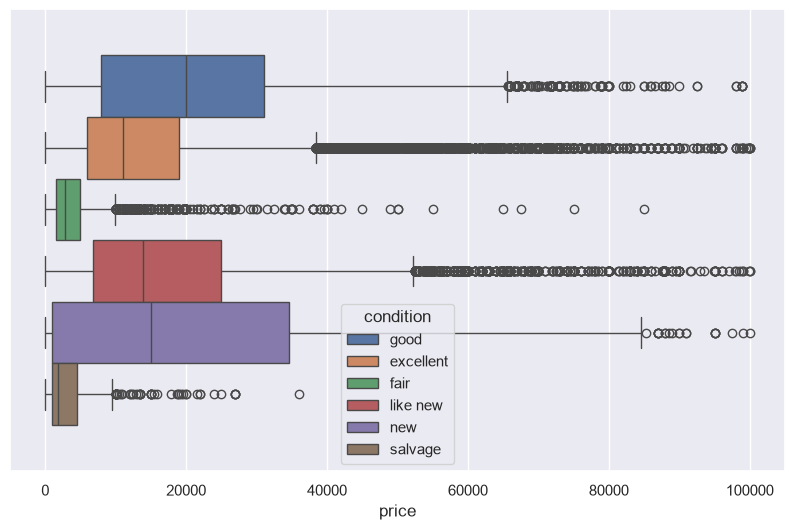

In [17]:
plt.figure(figsize=(10, 6))
sns.boxplot(data = data[data['price'] < 100000], x='price', hue ='condition')

C:\Users\Luka\AppData\Local\Temp\ipykernel_26972\1610546335.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data = data[data['price'] < 100000].sample(frac = 0.05), y='price', x ='year', palette = 'viridis', alpha = 0.7)


<Axes: xlabel='year', ylabel='price'>

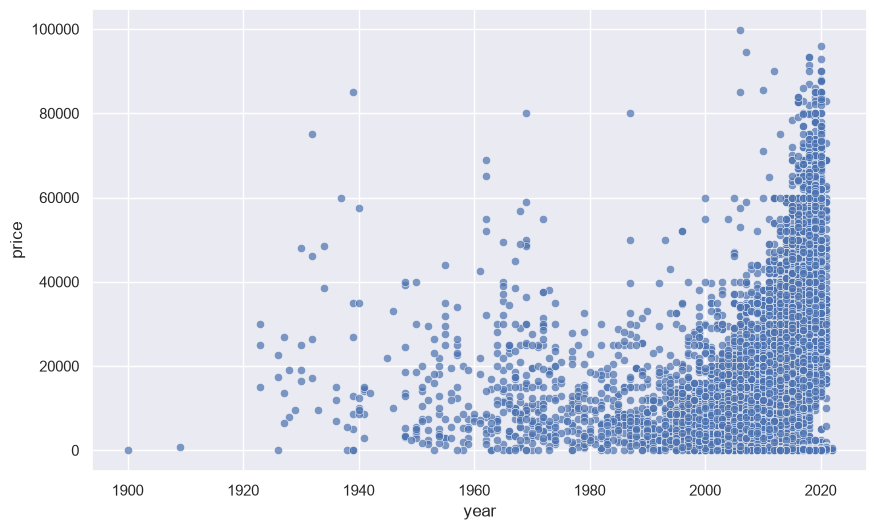

In [18]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data = data[data['price'] < 100000].sample(frac = 0.05), y='price', x ='year', palette = 'viridis', alpha = 0.7)

<Axes: xlabel='odometer', ylabel='price'>

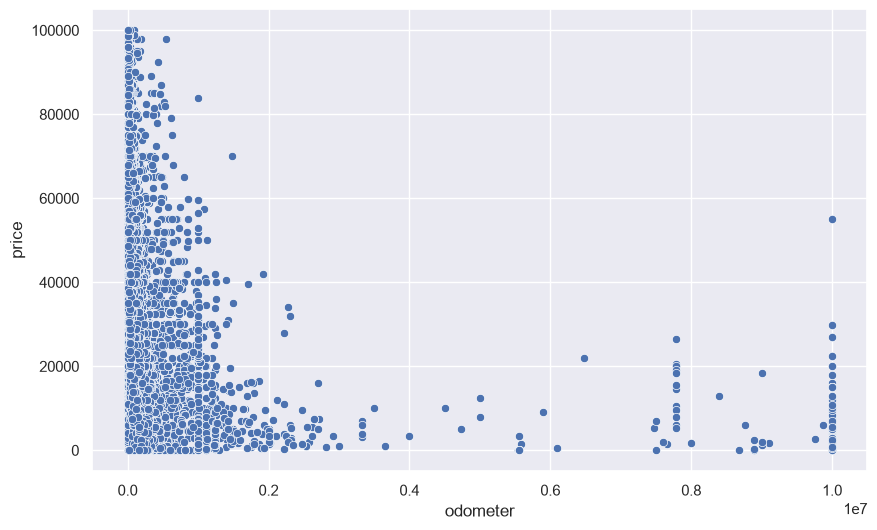

In [19]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data = data[data['price'] < 100000], y='price', x ='odometer')

<Axes: xlabel='year', ylabel='odometer'>

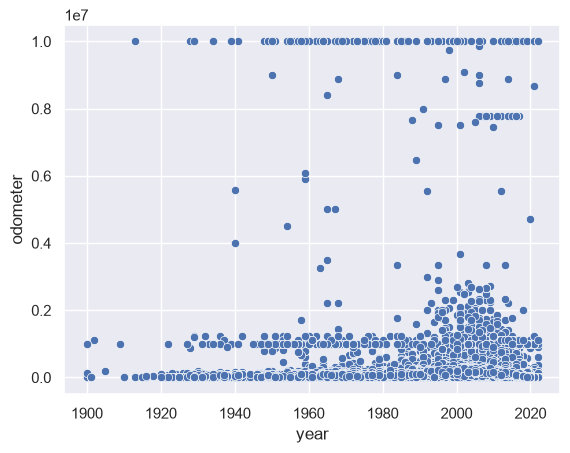

In [20]:
sns.scatterplot(data = data, y = 'odometer', x = 'year')

<Axes: xlabel='price'>

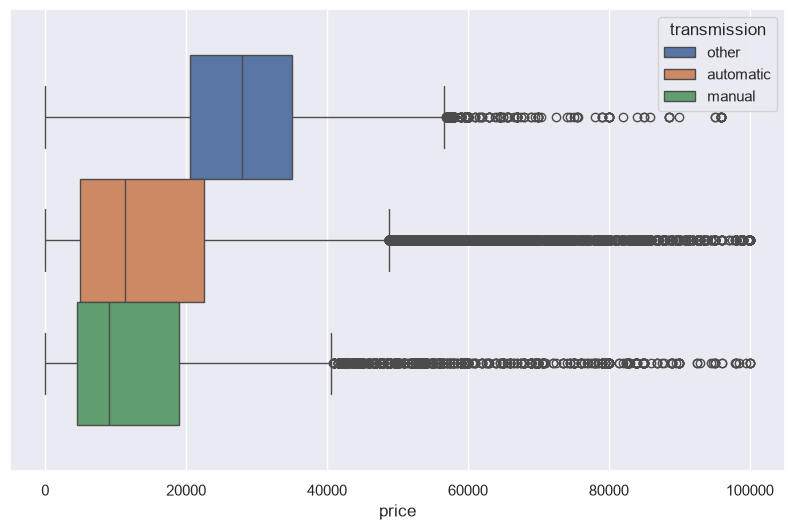

In [21]:
plt.figure(figsize=(10, 6))
sns.boxplot(data = data[data['price'] < 100000], x='price', hue ='transmission')

<Axes: xlabel='price'>

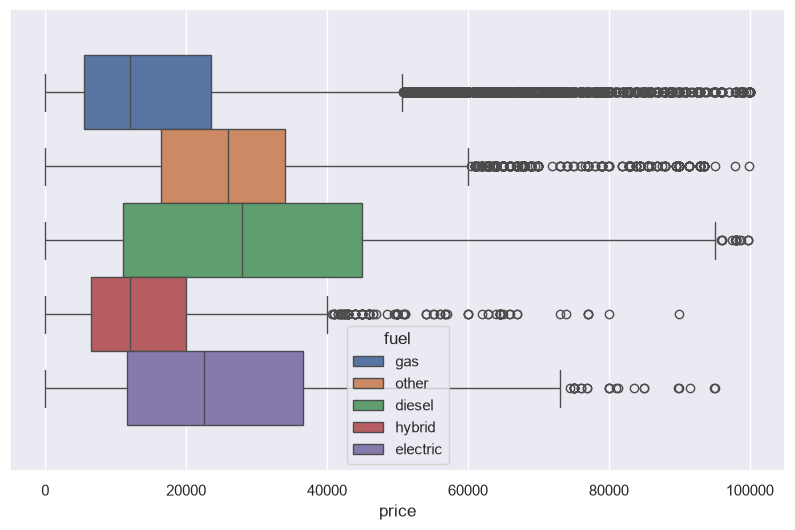

In [22]:
plt.figure(figsize=(10, 6))
sns.boxplot(data = data[data['price'] < 100000], x='price', hue ='fuel')

<Axes: xlabel='price'>

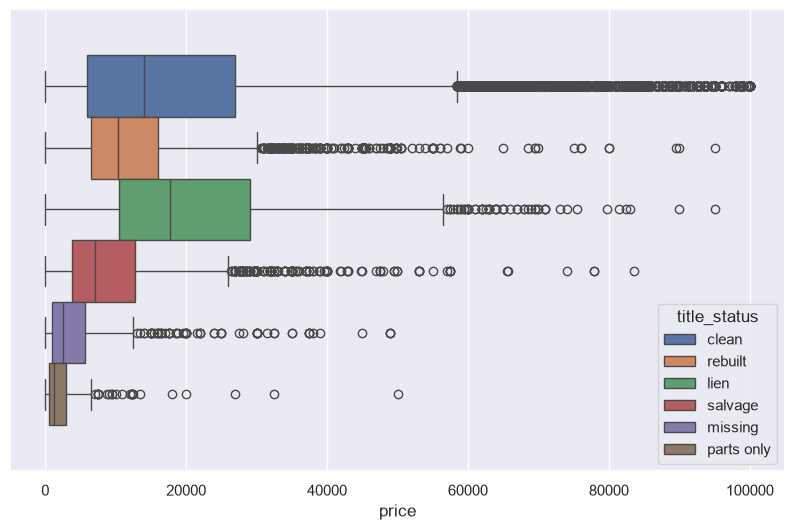

In [23]:
plt.figure(figsize=(10, 6))
sns.boxplot(data = data[data['price'] < 100000], x='price', hue ='title_status')

<Axes: xlabel='price'>

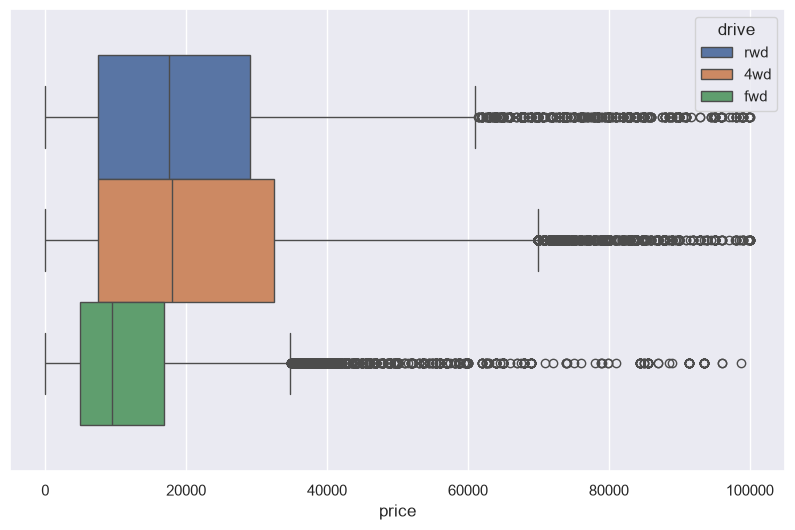

In [24]:
plt.figure(figsize=(10, 6))
sns.boxplot(data = data[data['price'] < 100000], x='price', hue ='drive')

<Axes: xlabel='price'>

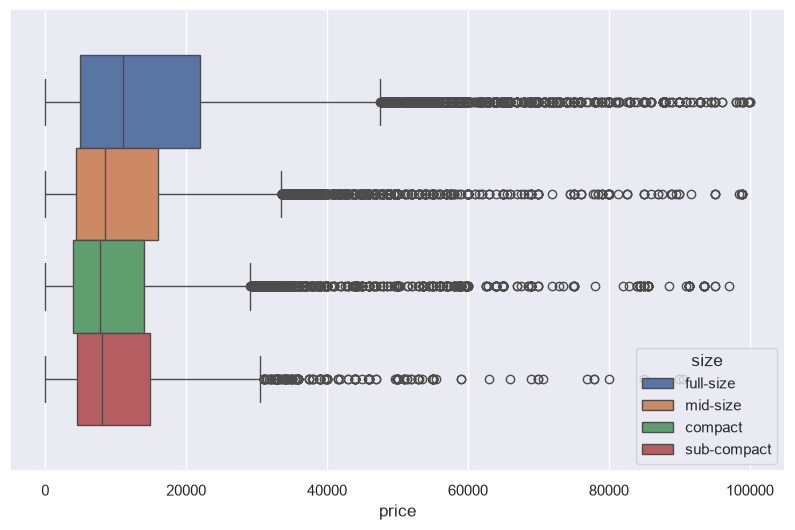

In [25]:
plt.figure(figsize=(10, 6))
sns.boxplot(data = data[data['price'] < 100000], x='price', hue ='size')

<Axes: xlabel='price'>

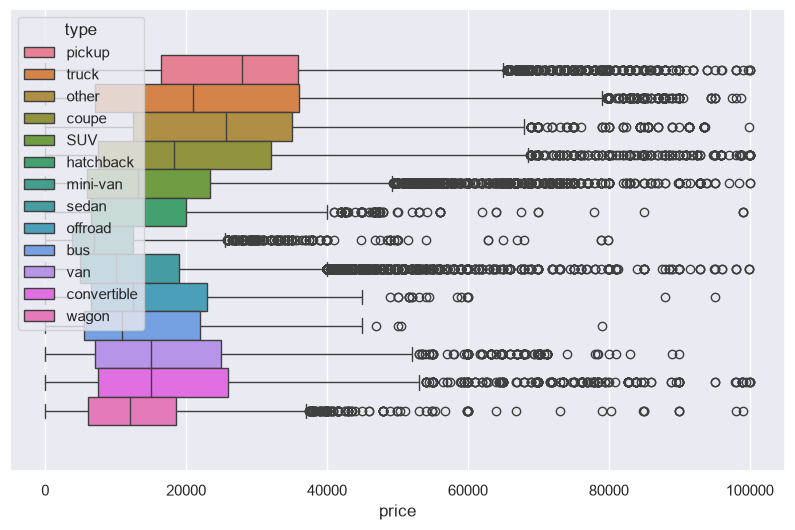

In [26]:
plt.figure(figsize=(10, 6))
sns.boxplot(data = data[data['price'] < 100000], x='price', hue ='type')

<Axes: xlabel='price'>

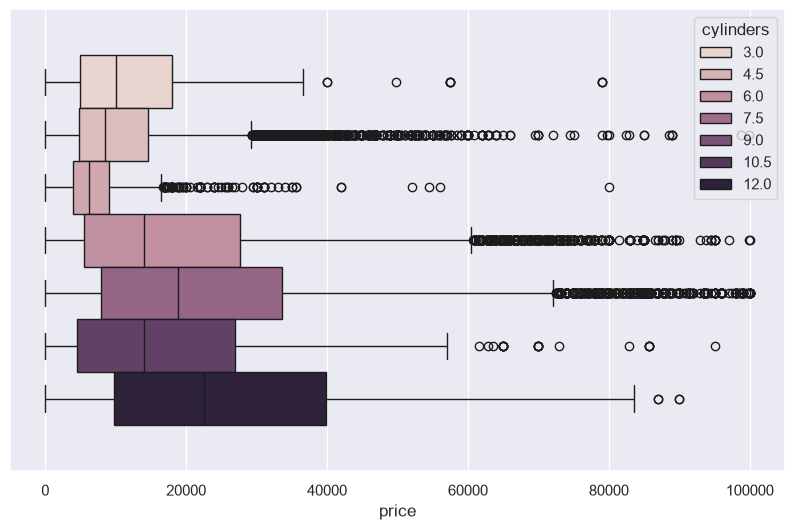

In [27]:
plt.figure(figsize=(10, 6))
sns.boxplot(data = data[data['price'] < 100000], x='price', hue ='cylinders')

### Feature selection and engineering

In [28]:
selected_cols = ['condition', 'year', 'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'drive', 'size', 'type', 'price']

In [29]:
def mi_score(data):
    
    data = data.copy()
        
    data = data.sample(frac=0.2, random_state=42)
        
    X, y = data.drop(columns=['price_clean']), data['price_clean']
    
    ordinal_cols = ['condition', 'title_status']
    
    categorical_cols = X.select_dtypes(include=['object']).columns.drop(ordinal_cols)
    
    numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns
    
    cat_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])
    
    ord_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ordinal', OrdinalEncoder(categories=[['salvage', 'fair', 'good', 'excellent', 'like new', 'new'], ['missing' ,'parts only' ,'salvage', 'rebuilt', 'lien', 'clean']]))
    ])
    num_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler())
    ])
    
    preprocessor = ColumnTransformer(
        transformers=[('num', num_transformer, numerical_cols), 
                      ('cat', cat_transformer, categorical_cols), 
                      ('ord', ord_transformer, ordinal_cols)])
    
    pipeline = Pipeline(steps=[('preprocessor', preprocessor)])
    
    X_transformed = pipeline.fit_transform(X)
    
    y = y.fillna(y.mean())
    
    mi_scores = mutual_info_regression(X_transformed, y)
    
    feature_names = pipeline.named_steps['preprocessor'].get_feature_names_out()
    
    return pd.Series(mi_scores, index=feature_names).sort_values(ascending=False)

In [30]:
# Remove outliers from the dataset to improve model performance and reduce skewness in the price distribution 
# using the Isolation Forest method. Fill outliers with the median value of the price column to maintain the integrity of the dataset.

def remove_outliers(data, method='isolation_forest', contamination=0.03):
    from sklearn.ensemble import IsolationForest
    
    data = data.copy()
    
    isolation_forest = IsolationForest(contamination=contamination, random_state=42)
    outliers = isolation_forest.fit_predict(data[['price']])
    
    data.loc[outliers == -1, 'price'] = data['price'].median()
        
    return data

In [31]:
data['price_clean'] = remove_outliers(data, method='isolation_forest', contamination=0.03)['price'] 

In [32]:
selected_cols = ['condition', 'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'drive', 'size', 'type', 'price_clean', 'age']

In [33]:
mi_scores = mi_score(data[selected_cols])

mi_scores

C:\Users\Luka\AppData\Local\Temp\ipykernel_26972\715563604.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=['object']).columns.drop(ordinal_cols)


num__odometer                  1.188373
num__age                       0.484673
cat__transmission_other        0.254447
cat__transmission_automatic    0.189300
num__cylinders                 0.141278
ord__condition                 0.125700
cat__drive_fwd                 0.075793
cat__fuel_gas                  0.065388
cat__type_sedan                0.054047
cat__fuel_other                0.051252
cat__fuel_diesel               0.051009
cat__drive_4wd                 0.048189
cat__type_pickup               0.048083
cat__type_truck                0.040081
cat__size_full-size            0.035591
cat__type_SUV                  0.027693
cat__type_other                0.027394
cat__type_hatchback            0.024957
cat__size_mid-size             0.023804
cat__transmission_manual       0.021607
cat__drive_rwd                 0.020868
ord__title_status              0.015956
cat__type_coupe                0.013441
cat__size_compact              0.011582
cat__type_wagon                0.010224


In [34]:
data['price'].describe()

count    4.268800e+05
mean     7.519903e+04
std      1.218228e+07
min      0.000000e+00
25%      5.900000e+03
50%      1.395000e+04
75%      2.648575e+04
max      3.736929e+09
Name: price, dtype: float64

In [35]:
round(data[data['price'] < 100000].groupby(['condition', 'title_status'])['price'].mean().unstack(), 0)

title_status,clean,lien,missing,parts only,rebuilt,salvage
condition,,,,,,
excellent,14339.0,24056.0,8004.0,8542.0,13809.0,12638.0
fair,3970.0,7910.0,2876.0,3403.0,3750.0,4033.0
good,20836.0,13869.0,5144.0,3175.0,9430.0,7492.0
like new,17805.0,30195.0,4734.0,2647.0,16571.0,14779.0
new,21602.0,37827.0,18947.0,9081.0,15375.0,12853.0
salvage,1896.0,3167.0,1363.0,1245.0,6925.0,5591.0


In [36]:
data['price'].loc[data['price'] > data['price'].quantile(0.95)].describe()

count    2.131100e+04
mean     1.215817e+06
std      5.451162e+07
min      4.450700e+04
25%      4.799700e+04
50%      5.370600e+04
75%      6.399500e+04
max      3.736929e+09
Name: price, dtype: float64

In [37]:
# Switch the 'price' column with the cleaned 'price_clean' column for further analysis and modeling.

selected_cols = ['condition', 'age', 'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'drive', 'size', 'type', 'price_clean']

In [38]:
def rf_test_columns(data, selected_cols):
    
    model = RandomForestRegressor(n_estimators=50, random_state=42, max_depth=10, min_samples_leaf=2,
                                  n_jobs=-1)

    data = data[selected_cols]
    
    data = data.copy()
    
    data = data.sample(frac=0.2, random_state=42)
    
    X, y = data.drop(columns=['price_clean']), data['price_clean']
        
    ordinal_col = ['condition']
    
    categorical_cols = X.select_dtypes(include=['object']).columns.drop(ordinal_col)
    
    numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns
    
    cat_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])
    
    ord_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ordinal', OrdinalEncoder(categories=[['salvage', 'fair', 'good', 'excellent', 'like new', 'new']]))
    ])
    num_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler())
    ])
    
    preprocessor = ColumnTransformer(
        transformers=[('num', num_transformer, numerical_cols), 
                      ('cat', cat_transformer, categorical_cols), 
                      ('ord', ord_transformer, ordinal_col)])
    
    valid = y.notnull()
    
    y = y.loc[valid]
        
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
        
    scores = cross_val_score(pipeline, X, y, cv=3, scoring= 'neg_mean_squared_error', n_jobs=-1)
    
    pipeline.fit(X, y)
    
    feature_importances = pipeline.named_steps['model'].feature_importances_
    
    return np.sqrt(-scores.mean()), pd.Series(feature_importances, index=pipeline.named_steps['preprocessor'].get_feature_names_out()).sort_values(ascending=False)


In [39]:
rf_score, rf_feature_importances = rf_test_columns(data, selected_cols)

print(f"Random Forest Squared Error: {rf_score:.4f}")
print("Random Forest Feature Importances:")
print(rf_feature_importances)

C:\Users\Luka\AppData\Local\Temp\ipykernel_26972\2073603272.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=['object']).columns.drop(ordinal_col)


Random Forest Squared Error: 8633.0075
Random Forest Feature Importances:
num__age                        4.402500e-01
num__odometer                   1.485877e-01
cat__transmission_other         1.037599e-01
cat__drive_fwd                  7.493428e-02
cat__fuel_diesel                6.186975e-02
num__cylinders                  5.974891e-02
cat__type_pickup                2.991404e-02
ord__condition                  2.057163e-02
cat__type_truck                 1.209249e-02
cat__fuel_gas                   9.975907e-03
cat__type_sedan                 6.880524e-03
cat__size_full-size             6.235564e-03
cat__type_hatchback             2.511381e-03
cat__drive_4wd                  2.429312e-03
cat__fuel_other                 2.299034e-03
cat__type_other                 2.077375e-03
cat__drive_rwd                  2.044771e-03
cat__size_compact               1.872302e-03
cat__type_SUV                   1.836977e-03
cat__transmission_automatic     1.245137e-03
cat__title_status_rebuilt 

In [40]:
def xgboost_test_columns(data, selected_cols):
    
    
    model = XGBRegressor(n_estimators=100, random_state=42, max_depth=6, learning_rate=0.1, n_jobs=-1)

    data = data[selected_cols]
    
    data = data.copy()
    
    data = data.sample(frac=0.2, random_state=42)
    
    X, y = data.drop(columns=['price_clean']), data['price_clean']
        
    ordinal_col = ['condition']
    
    categorical_cols = X.select_dtypes(include=['object']).columns.drop(ordinal_col)
    
    numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns
    
    cat_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])
    
    ord_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ordinal', OrdinalEncoder(categories=[['salvage', 'fair', 'good', 'excellent', 'like new', 'new']]))
    ])
    num_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler())
    ])
    
    preprocessor = ColumnTransformer(
        transformers=[('num', num_transformer, numerical_cols), 
                      ('cat', cat_transformer, categorical_cols), 
                      ('ord', ord_transformer, ordinal_col)])
    
    valid = y.notnull()
    
    y = y.loc[valid]
    
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    
    scores = cross_val_score(pipeline, X, y, cv=3, scoring= 'neg_mean_squared_error', n_jobs=-1)
    
    pipeline.fit(X, y)
    
    feature_importances = pipeline.named_steps['model'].feature_importances_
    
    return np.sqrt(-scores.mean()), pd.Series(feature_importances, index=pipeline.named_steps['preprocessor'].get_feature_names_out()).sort_values(ascending=False)

In [41]:
xgb_score, xgb_feature_importances = xgboost_test_columns(data, selected_cols)

print(f"XGBoost Squared Error: {xgb_score:.4f}")
print("XGBoost Feature Importances:")
xgb_feature_importances

C:\Users\Luka\AppData\Local\Temp\ipykernel_26972\2537489886.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=['object']).columns.drop(ordinal_col)


XGBoost Squared Error: 8550.5705
XGBoost Feature Importances:


cat__transmission_other         0.267913
cat__drive_fwd                  0.118451
cat__fuel_diesel                0.093150
num__age                        0.072119
cat__type_pickup                0.066292
cat__fuel_gas                   0.037568
cat__type_sedan                 0.033322
num__cylinders                  0.032717
num__odometer                   0.029898
cat__size_full-size             0.023744
cat__title_status_rebuilt       0.021492
cat__type_hatchback             0.021305
cat__type_truck                 0.021195
ord__condition                  0.015670
cat__drive_rwd                  0.012018
cat__type_SUV                   0.010668
cat__size_compact               0.010261
cat__title_status_lien          0.009560
cat__type_van                   0.008515
cat__title_status_clean         0.008264
cat__type_other                 0.008250
cat__drive_4wd                  0.007466
cat__title_status_salvage       0.007101
cat__fuel_hybrid                0.006921
cat__fuel_other 

In [42]:
# What to do next:
# 1. Check the feature importances and see if any features can be dropped or transformed to improve model performance.
# 2. Explore whether additional feature engineering or hyperparameter tuning can enhance the model's predictive capabilities.

In [43]:
data.columns

Index(['id', 'url', 'region', 'region_url', 'price', 'year', 'manufacturer',
       'model', 'condition', 'cylinders', 'fuel', 'odometer', 'title_status',
       'transmission', 'vin', 'drive', 'size', 'type', 'paint_color',
       'image_url', 'description', 'county', 'state', 'lat', 'long',
       'posting_date', 'age', 'price_clean'],
      dtype='str')

In [44]:
# Make latitude and longitude scatter plot to visualize the distribution of car prices across different locations in the United States, 
# with color intensity representing the price of the cars. This can help identify any geographical trends or clusters in car pricing.

data['lat_us'] = data[data['lat'].between(24.396308, 49.384358)]['lat']
data['long_us'] = data[data['long'].between(-124, -66)]['long']

<Axes: xlabel='lat_us', ylabel='long_us'>

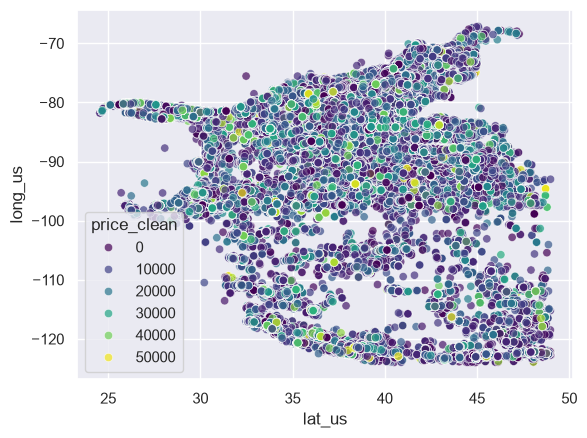

In [45]:
sns.scatterplot(x = 'lat_us', y = 'long_us', hue = 'price_clean', data = data, palette = 'viridis', alpha = 0.7)

In [46]:
# See how many rows are dropped when filtering for valid latitude and longitude values within the United States. 
# This can help assess the impact of geographical filtering on the dataset size and distribution.

data_dropped_us_ratio = 1 - len(data.dropna(subset=['lat_us', 'long_us'])) / len(data)
data_dropped_us_ratio

# It is around 0.03%, which indicates that the geographical filtering does not significantly reduce the dataset size,
# allowing for a more focused analysis of car prices within the United States.

0.0316435532233883

In [47]:
def kmeans_location(data, n_clusters):
    from sklearn.cluster import KMeans
    
    data = data.copy()
    
    data = data.dropna(subset=['lat_us', 'long_us'])
    
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    
    data['location_cluster'] = kmeans.fit_predict(data[['lat_us', 'long_us']])
    
    return data, kmeans

In [48]:
kmeans_data, kmeans_model = kmeans_location(data, n_clusters=10)

<Axes: xlabel='lat_us', ylabel='long_us'>

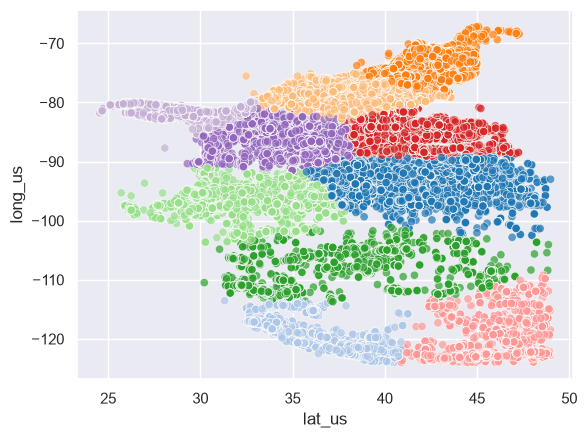

In [49]:
# Plot the clusters on a scatter plot to visualize the geographical distribution of car prices across different locations in the United States,
# with color intensity representing the price of the cars. This can help identify any geographical trends or clusters in car pricing.

sns.scatterplot(x = 'lat_us', y = 'long_us', hue = 'location_cluster', data = kmeans_data, palette = 'tab20', alpha = 0.7, legend=False
                )